# 05 · Skema walk-forward, blok validasi, dan purge

**Bab 3 Subbab 3.8, 3.9.1, 3.9.2.**

- **Masker bersama**: observasi dipakai bila fitur K2 layak dan label layak. K1, K2, K3, dan kedua model memakai bar
  uji yang **sama**; K3 tidak mengurangi bar karena nilai makro yang kosong diimputasi dari data latih.
- **Periode uji** (7): interval setengah terbuka UTC. Observasi uji = keputusan di dalam periode **dan** akhir label
  juga di dalam periode.
- **Data latih** (*expanding window*): semua observasi yang akhir labelnya **sebelum waktu keputusan pertama** pada blok
  berikutnya. Aturan ini membuang bar terakhir yang labelnya menyeberang ke blok uji: **purge**.
- **Validasi internal**: 18 bulan terakhir sebelum periode uji dibagi tiga blok enam bulanan; tiap blok dilatih dengan
  seluruh riwayat sebelumnya, dengan purge yang sama.

**Input:** `02_label.parquet`, `03_fitur.parquet`, `04_fitur_makro.parquet`
**Output:** `05_dataset.parquet`, `05_blok.csv`

In [1]:
import tomllib
from pathlib import Path

# Cari folder proyek (folder yang memuat configs/phase4-p0.toml) agar notebook bisa dijalankan dari mana saja.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/phase4-p0.toml").exists())
CFG = tomllib.loads((ROOT / "configs/phase4-p0.toml").read_text(encoding="utf-8"))
OUT = ROOT / "data/interim/phase4-p0"     # folder hasil; diabaikan Git karena memuat data vendor
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
import pandas as pd

label = pd.read_parquet(OUT / "02_label.parquet")
fitur = pd.read_parquet(OUT / "03_fitur.parquet").drop(columns=["sigma_24"])
makro = pd.read_parquet(OUT / "04_fitur_makro.parquet")
df = label.merge(fitur, on="time", validate="1:1").merge(makro, on="time", validate="1:1")

df = df[df["fitur_layak"] & df["target_layak"]].reset_index(drop=True)
print("Observasi layak (masker bersama):", len(df))

Observasi layak (masker bersama): 36649


## 1. Batas periode uji dan blok validasi

In [3]:
def batas_blok(df, awal, akhir):
    """Observasi pada blok [awal, akhir) dan waktu keputusan pertamanya."""
    di_blok = (df["decision_time"] >= awal) & (df["decision_time"] < akhir) & (df["target_end_time"] < akhir)
    return di_blok, df.loc[di_blok, "decision_time"].min()


V = CFG["validasi"]
baris = []
for nama, awal, akhir in V["periode_uji"]:
    awal, akhir = pd.Timestamp(awal), pd.Timestamp(akhir)
    mulai_validasi = awal - pd.DateOffset(months=V["inner_validation_months"])
    for i in range(V["inner_validation_months"] // V["inner_block_months"]):
        a = mulai_validasi + pd.DateOffset(months=i * V["inner_block_months"])
        b = a + pd.DateOffset(months=V["inner_block_months"])
        baris.append({"periode": nama, "blok": f"validasi-{i + 1}", "awal": a, "akhir": b})
    baris.append({"periode": nama, "blok": "uji", "awal": awal, "akhir": akhir})
blok = pd.DataFrame(baris)

ringkas = []
for r in blok.itertuples():
    di_blok, pertama = batas_blok(df, r.awal, r.akhir)
    latih = df["target_end_time"] < pertama
    hitung = df.loc[latih, "label_0p5"].value_counts()
    ringkas.append({
        "keputusan_pertama": pertama,
        "n_latih": int(latih.sum()),
        "n_blok": int(di_blok.sum()),
        "dibuang_purge": int(((df["decision_time"] < r.awal) & (df["target_end_time"] >= pertama)).sum()),
        "latih_3_kelas": all(hitung.get(k, 0) > 0 for k in ("BUY", "HOLD", "SELL")),
    })
blok = pd.concat([blok, pd.DataFrame(ringkas)], axis=1)
blok

,periode,blok,awal,akhir,keputusan_pertama,n_latih,n_blok,dibuang_purge,latih_3_kelas
0,2023-H1,validasi-1,2021-07-01 00:00:00+00:00,2022-01-01 00:00:00+00:00,2021-07-01 02:00:00+00:00,8279,2814,0,True
1,2023-H1,validasi-2,2022-01-01 00:00:00+00:00,2022-07-01 00:00:00+00:00,2022-01-03 02:00:00+00:00,11093,2807,0,True
2,2023-H1,validasi-3,2022-07-01 00:00:00+00:00,2023-01-01 00:00:00+00:00,2022-07-01 02:00:00+00:00,13901,2851,0,True
3,2023-H1,uji,2023-01-01 00:00:00+00:00,2023-07-01 00:00:00+00:00,2023-01-03 02:00:00+00:00,16752,2807,0,True
4,2023-H2,validasi-1,2022-01-01 00:00:00+00:00,2022-07-01 00:00:00+00:00,2022-01-03 02:00:00+00:00,11093,2807,0,True
5,2023-H2,validasi-2,2022-07-01 00:00:00+00:00,2023-01-01 00:00:00+00:00,2022-07-01 02:00:00+00:00,13901,2851,0,True
6,2023-H2,validasi-3,2023-01-01 00:00:00+00:00,2023-07-01 00:00:00+00:00,2023-01-03 02:00:00+00:00,16752,2807,0,True
7,2023-H2,uji,2023-07-01 00:00:00+00:00,2024-01-01 00:00:00+00:00,2023-07-03 02:00:00+00:00,19560,2829,0,True
8,2024-H1,validasi-1,2022-07-01 00:00:00+00:00,2023-01-01 00:00:00+00:00,2022-07-01 02:00:00+00:00,13901,2851,0,True
9,2024-H1,validasi-2,2023-01-01 00:00:00+00:00,2023-07-01 00:00:00+00:00,2023-01-03 02:00:00+00:00,16752,2807,0,True


`dibuang_purge` adalah observasi sebelum awal blok yang labelnya baru berakhir pada atau setelah keputusan pertama blok
tersebut. Nilainya kecil (satu bar per pemisahan), sesuai Bab 3 "purge sedikitnya satu bar H1".

Semua data latih harus memuat tiga kelas; bila tidak, blok itu dicatat sebagai kegagalan evaluasi.

In [4]:
assert blok["latih_3_kelas"].all()
assert (blok["n_blok"] > 0).all()

uji = blok[blok["blok"] == "uji"].set_index("periode")
kelas_uji = {}
for nama, r in uji.iterrows():
    di_blok, _ = batas_blok(df, r["awal"], r["akhir"])
    kelas_uji[nama] = df.loc[di_blok, "label_0p5"].value_counts().reindex(["BUY", "HOLD", "SELL"])
pd.DataFrame(kelas_uji).T.assign(total=lambda t: t.sum(axis=1))

label_0p5,BUY,HOLD,SELL,total
2023-H1,699,1410,698,2807
2023-H2,669,1470,690,2829
2024-H1,740,1385,683,2808
2024-H2,830,1380,660,2870
2025-H1,816,1228,690,2734
2025-H2,837,1218,689,2744
2026-Jan-Jul,809,1501,791,3101


## 2. Gambar skema walk-forward

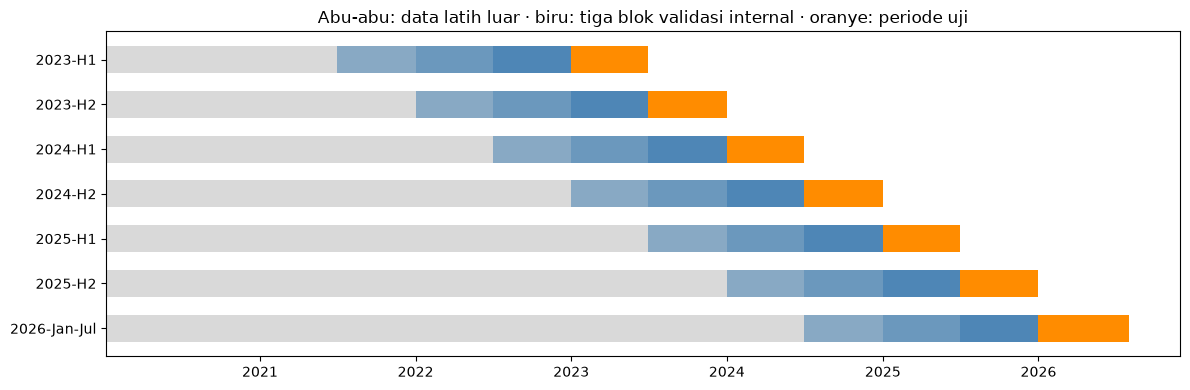

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt


def batang(ax, y, a, b, **gaya):
    a, b = mdates.date2num(a.to_pydatetime()), mdates.date2num(b.to_pydatetime())
    ax.barh(y, b - a, left=a, height=0.6, **gaya)


fig, ax = plt.subplots(figsize=(12, 4))
awal_data = df["decision_time"].min()
for i, (nama, g) in enumerate(blok.groupby("periode", sort=False)):
    y = len(uji) - i
    r_uji = g[g["blok"] == "uji"].iloc[0]
    batang(ax, y, awal_data, r_uji["awal"], color="0.85")
    for r in g[g["blok"] != "uji"].itertuples():
        batang(ax, y, r.awal, r.akhir, color="steelblue", alpha=0.35 + 0.2 * int(r.blok[-1]))
    batang(ax, y, r_uji["awal"], r_uji["akhir"], color="darkorange")
ax.xaxis_date()
ax.set_yticks(range(len(uji), 0, -1), uji.index)
ax.set_title("Abu-abu: data latih luar · biru: tiga blok validasi internal · oranye: periode uji")
plt.tight_layout()

In [6]:
df.to_parquet(OUT / "05_dataset.parquet", index=False)
blok.to_csv(OUT / "05_blok.csv", index=False)
print("Tersimpan:", (OUT / "05_dataset.parquet").relative_to(ROOT), df.shape, "dan 05_blok.csv")

Tersimpan: data/interim/phase4-p0/05_dataset.parquet (36649, 71) dan 05_blok.csv
